# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [10]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [11]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [12]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [13]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [14]:
# Kiểm tra 3 hàm trả về cùng số xung đột trên cùng các bàn cờ
test_sizes = [4, 8, 20, 50]
for n in test_sizes:
    for _ in range(10):
        board = random_board(n)
        naive_score = conflicts_naive(board)
        linear_score = conflicts(board)
        jit_score = conflicts_jit(board)

        assert naive_score == linear_score == jit_score, (
            f"Không khớp tại n={n}: "
            f"{naive_score}, {linear_score}, {jit_score}"
        )

print("Kiểm tra thành công: conflicts_naive, conflicts và conflicts_jit cho kết quả giống nhau.")

Kiểm tra thành công: conflicts_naive, conflicts và conflicts_jit cho kết quả giống nhau.


In [15]:
import timeit
import numpy as np
import matplotlib.pyplot as plt

# Quan trọng: gọi trước một lần để loại thời gian biên dịch JIT khỏi phép đo
conflicts_jit(random_board(8))

sizes = [8, 25, 50, 100, 200, 300, 400]
boards_per_size = 10
repeats = 3

naive_times = []
linear_times = []
jit_times = []

for n in sizes:
    boards = [random_board(n) for _ in range(boards_per_size)]

    # Lấy thời gian tốt nhất trong vài lần đo để giảm nhiễu từ hệ thống
    naive = min(timeit.repeat(
        lambda: [conflicts_naive(board) for board in boards],
        repeat=repeats, number=1
    ))
    linear = min(timeit.repeat(
        lambda: [conflicts(board) for board in boards],
        repeat=repeats, number=1
    ))
    jit = min(timeit.repeat(
        lambda: [conflicts_jit(board) for board in boards],
        repeat=repeats, number=1
    ))

    # Thời gian trung bình trên một bàn cờ, đơn vị micro giây
    naive_times.append(naive / boards_per_size * 1e6)
    linear_times.append(linear / boards_per_size * 1e6)
    jit_times.append(jit / boards_per_size * 1e6)

# Bảng thời gian
import pandas as pd
timing_results = pd.DataFrame({
    "Board size (n)": sizes,
    "Naive O(n^2) (µs/board)": naive_times,
    "Linear O(n) (µs/board)": linear_times,
    "Numba JIT O(n) (µs/board)": jit_times
})
display(timing_results.round(2))

# Tính hệ số tăng tốc của Numba so với bản O(n) Python
print("\nSpeedup của Numba so với conflicts() (O(n) Python):")
for n, py_time, jit_time in zip(sizes, linear_times, jit_times):
    print(f"n={n:3d}: {py_time / jit_time:.2f}x")

,Board size (n),Naive O(n^2) (µs/board),Linear O(n) (µs/board),Numba JIT O(n) (µs/board)
0,8,39.68,9.69,0.53
1,25,175.67,28.32,0.66
2,50,541.46,55.13,1.07
3,100,1806.43,109.76,1.44
4,200,6395.81,215.70,2.28
5,300,13665.34,321.37,3.09
6,400,23551.77,423.43,3.88



Speedup của Numba so với conflicts() (O(n) Python):
n=  8: 18.28x
n= 25: 42.91x
n= 50: 51.52x
n=100: 76.22x
n=200: 94.61x
n=300: 104.00x
n=400: 109.13x


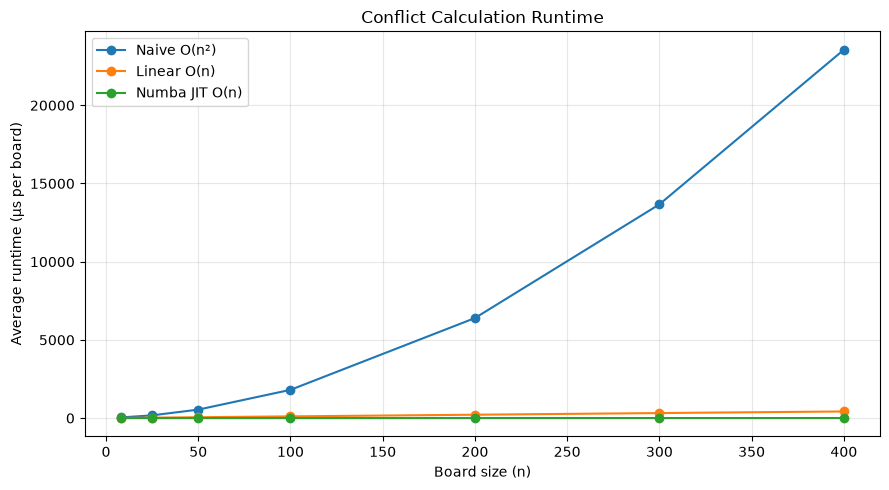

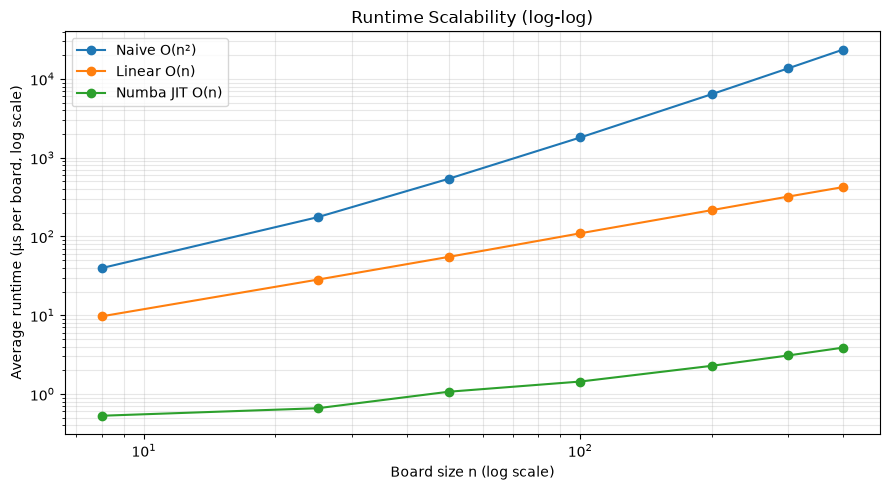

In [16]:
# Biểu đồ 1: thời gian chạy theo kích thước bàn cờ
plt.figure(figsize=(9, 5))
plt.plot(sizes, naive_times, marker="o", label="Naive O(n²)")
plt.plot(sizes, linear_times, marker="o", label="Linear O(n)")
plt.plot(sizes, jit_times, marker="o", label="Numba JIT O(n)")
plt.xlabel("Board size (n)")
plt.ylabel("Average runtime (µs per board)")
plt.title("Conflict Calculation Runtime")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Biểu đồ 2: log-log để quan sát xu hướng tăng theo kích thước
plt.figure(figsize=(9, 5))
plt.loglog(sizes, naive_times, marker="o", label="Naive O(n²)")
plt.loglog(sizes, linear_times, marker="o", label="Linear O(n)")
plt.loglog(sizes, jit_times, marker="o", label="Numba JIT O(n)")
plt.xlabel("Board size n (log scale)")
plt.ylabel("Average runtime (µs per board, log scale)")
plt.title("Runtime Scalability (log-log)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Nhận xét kết quả

- `conflicts_naive()` duyệt các cặp quân hậu theo đường chéo nên có độ phức tạp thời gian **O(n²)**.
- `conflicts()` đếm số quân theo hàng và hai hướng đường chéo, sau đó cộng \(C(k,2)=k(k-1)/2\), nên có độ phức tạp **O(n)**.
- `conflicts_jit()` dùng cùng ý tưởng đếm với `conflicts()` nhưng được biên dịch bằng Numba `@njit`. Độ phức tạp thuật toán vẫn là **O(n)**; JIT chủ yếu giảm hằng số thời gian thực thi bằng cách biên dịch vòng lặp Python sang mã máy.
- Lần gọi `conflicts_jit()` đầu tiên có thể chậm do chi phí biên dịch. Vì vậy, notebook gọi hàm một lần trước khi đo thời gian.
- Kết quả benchmark có thể khác nhau tùy máy, phiên bản Python/Numba và tải hệ thống. Nên dựa vào xu hướng trên biểu đồ thay vì xem thời gian là giá trị tuyệt đối.